<a href="https://colab.research.google.com/github/Rashibh-1008/mlprojectonheartdisease/blob/main/Heart_Disease_PRML_Pipeline_5000_(1)_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease Risk Prediction: Complete Machine Learning Pipeline

**Course:** PRML  |  **Dataset:** Cardiovascular Disease dataset (Kaggle, 70,000 patient records). We take a **stratified random sample of 5,000 patients** with **12 features** and predict whether the patient has **cardiovascular (heart) disease** (`cardio`: 0 = no, 1 = yes).

| Assignment requirement | Where in this notebook |
|---|---|
| Tabular dataset| Section 2 (5,000 samples, 12 features) |
| EDA | Section 3 |
| Classification, complete ML pipeline | Sections 4, 6 |
| K-Means (elbow curve, best k) and DBSCAN | Section 5 |
| Models with all features | Section 6 |
| Feature selection (scikit-learn techniques) | Section 7 |
| PCA and model development using PCA | Section 8 |
| Stratified K-Fold evaluation | Sections 4, 6 to 9 |
| Ensemble: hard voting and soft voting | Section 9 |
| Final test-set evaluation and conclusions | Sections 10 and 11 |

> **Note on the target:** this large public heart dataset has a **binary** label (disease / no disease). The pipeline code (stratified splits, macro-F1, confusion matrix) is written for any number of classes.



## 1. Setup: import libraries

### Concepts in Section 1: Setup and Libraries
In this section, we import essential machine learning libraries from `scikit-learn` along with numerical and plotting utilities:
* **Pipelines & ColumnTransformer:** Used to stack feature engineering and model training cleanly, avoiding data leakage during evaluation.
* **Feature Selectors (e.g., VarianceThreshold, SelectKBest, RFE):** Integrated to identify the most robust heart disease indicators.
* **Ensemble Classifiers (Voting, AdaBoost):** Employed to pool predictions from multiple algorithms to maximize accuracy and F1 score.

In [ ]:
import warnings, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, AdaBoostClassifier
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from functools import partial
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif,
                                       mutual_info_classif, RFE, SelectFromModel)
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42   # fixed seed so results are reproducible

## 2. Load the dataset

The full file has 70,000 patients, far more than needed. Steps: (1) remove physically impossible records (e.g. blood pressure of 16000, height 55 cm), (2) convert age from days to years and add **BMI**, (3) draw a **stratified random sample of 5,000 patients** (both classes keep their original proportion). This satisfies the "more than 5000 samples" condition and keeps training fast.

* **Continuous (6):** `age_years`, `height`, `weight`, `ap_hi` (systolic BP), `ap_lo` (diastolic BP), `bmi`
* **Categorical (6):** `gender`, `cholesterol` (1 normal, 2 above, 3 well above), `gluc` (glucose, same scale), `smoke`, `alco`, `active`
* **Target:** `cardio` (0 = no disease, 1 = disease)

In [ ]:
RAW_URL = ("https://raw.githubusercontent.com/Manash-git/"
           "Kaggle-Cardiovascular-Disease-Prediction-using-Random-Forest/main/datasets/cardio_train.csv")

def load_cardio_raw():
    if os.path.exists("cardio_train.csv"):
        return pd.read_csv("cardio_train.csv", sep=";")
    return pd.read_csv(RAW_URL, sep=";")
N_SAMPLES = 5000
raw = load_cardio_raw()
print("Raw records:", raw.shape)

valid = (raw["ap_hi"].between(70, 250) & raw["ap_lo"].between(40, 200) & (raw["ap_hi"] > raw["ap_lo"])
         & raw["height"].between(120, 220) & raw["weight"].between(30, 200))
print("Removed impossible records:", int((~valid).sum()))
clean = raw[valid].copy()
clean["age_years"] = clean["age"] / 365.25
clean["bmi"] = clean["weight"] / (clean["height"] / 100) ** 2
clean = clean.drop(columns=["id", "age"])

# stratified random sample of 5000 patients
df, _ = train_test_split(clean, train_size=N_SAMPLES, stratify=clean["cardio"], random_state=RANDOM_STATE)
df = df.reset_index(drop=True)

class_names = {0: "No disease", 1: "Heart disease"}
num_cols = ["age_years", "height", "weight", "ap_hi", "ap_lo", "bmi"]
cat_cols = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

X = df[num_cols + cat_cols]
y = df["cardio"]
print("\nSampled dataset shape:", df.shape)
print("Features             :", X.shape[1])
print("Classes              :", y.nunique())

Raw records: (70000, 13)
Removed impossible records: 1385

Sampled dataset shape: (5000, 13)
Features             : 12
Classes              : 2


## 3. Exploratory Data Analysis (EDA)

### 3.1 First look: shape, types, missing values, duplicates

In [ ]:
display(df.head())
df.info()

,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi
0,1,165,63.0,120,80,1,1,0,0,1,0,39.997262,23.140496
1,1,160,57.0,120,80,1,1,0,0,1,0,60.260096,22.265625
2,1,164,65.0,120,80,1,1,0,0,0,0,63.753593,24.167162
3,1,161,100.0,140,80,3,3,0,0,1,1,56.202601,38.578759
4,1,154,76.0,160,100,1,1,0,1,1,0,41.864476,32.045876


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   gender       5000 non-null   int64  
 1   height       5000 non-null   int64  
 2   weight       5000 non-null   float64
 3   ap_hi        5000 non-null   int64  
 4   ap_lo        5000 non-null   int64  
 5   cholesterol  5000 non-null   int64  
 6   gluc         5000 non-null   int64  
 7   smoke        5000 non-null   int64  
 8   alco         5000 non-null   int64  
 9   active       5000 non-null   int64  
 10  cardio       5000 non-null   int64  
 11  age_years    5000 non-null   float64
 12  bmi          5000 non-null   float64
dtypes: float64(3), int64(10)
memory usage: 507.9 KB


In [ ]:
display(df.describe().T.round(2))
print("Missing values  :", int(df.isnull().sum().sum()))
print("Duplicate rows  :", int(df.duplicated().sum()))

,count,mean,std,min,25%,50%,75%,max
gender,5000.0,1.35,0.48,1.00,1.00,1.00,2.00,2.00
height,5000.0,164.28,7.97,120.00,159.00,165.00,169.00,196.00
weight,5000.0,73.88,14.40,36.00,64.00,72.00,81.00,200.00
ap_hi,5000.0,126.76,16.53,70.00,120.00,120.00,140.00,210.00
ap_lo,5000.0,81.26,9.37,40.00,80.00,80.00,90.00,120.00
cholesterol,5000.0,1.37,0.68,1.00,1.00,1.00,2.00,3.00
gluc,5000.0,1.22,0.57,1.00,1.00,1.00,1.00,3.00
smoke,5000.0,0.09,0.28,0.00,0.00,0.00,0.00,1.00
alco,5000.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00
active,5000.0,0.80,0.40,0.00,1.00,1.00,1.00,1.00


Missing values  : 0
Duplicate rows  : 0


### 3.2 Target distribution (is the data balanced?)

,count,percent
cardio,,
No disease,2526,50.52
Heart disease,2474,49.48


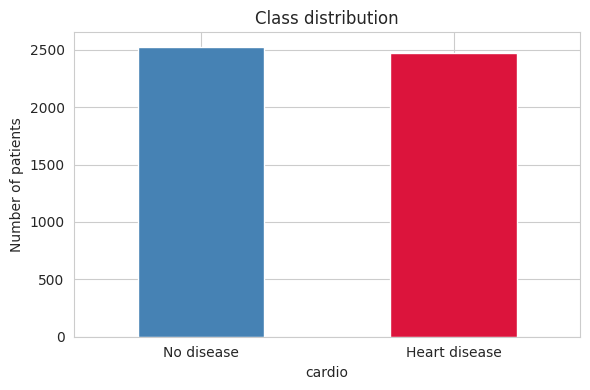

In [ ]:
counts = df["cardio"].map(class_names).value_counts()
summary = counts.to_frame("count")
summary["percent"] = (100 * summary["count"] / len(df)).round(2)
display(summary)
counts.plot(kind="bar", figsize=(6, 4), color=["steelblue", "crimson"])
plt.title("Class distribution"); plt.ylabel("Number of patients")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 3.3 Distribution of the continuous features

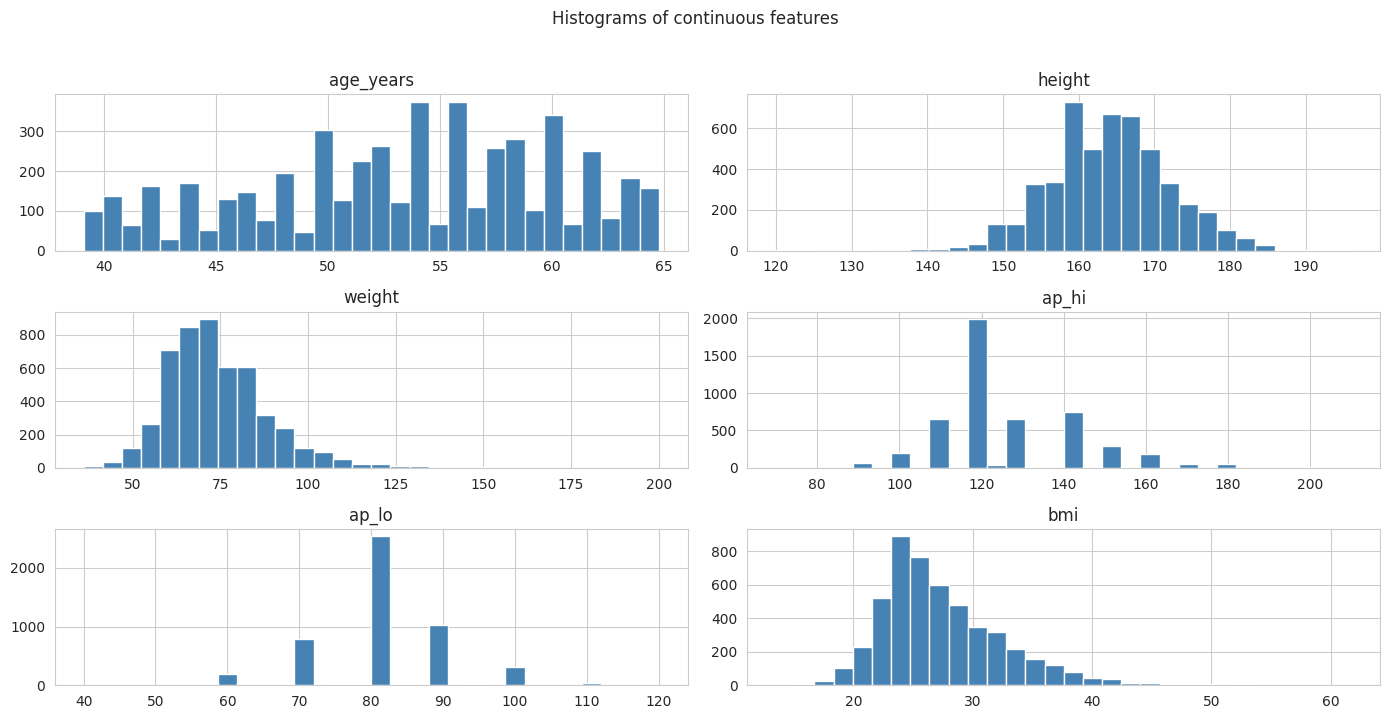

In [ ]:
df[num_cols].hist(bins=30, figsize=(14, 7), color="steelblue", edgecolor="white")
plt.suptitle("Histograms of continuous features", y=1.02)
plt.tight_layout(); plt.show()

### 3.4 Outliers (IQR rule)

,outliers,percent
age_years,0,0.00
height,52,1.04
weight,140,2.80
ap_hi,78,1.56
ap_lo,244,4.88
bmi,129,2.58


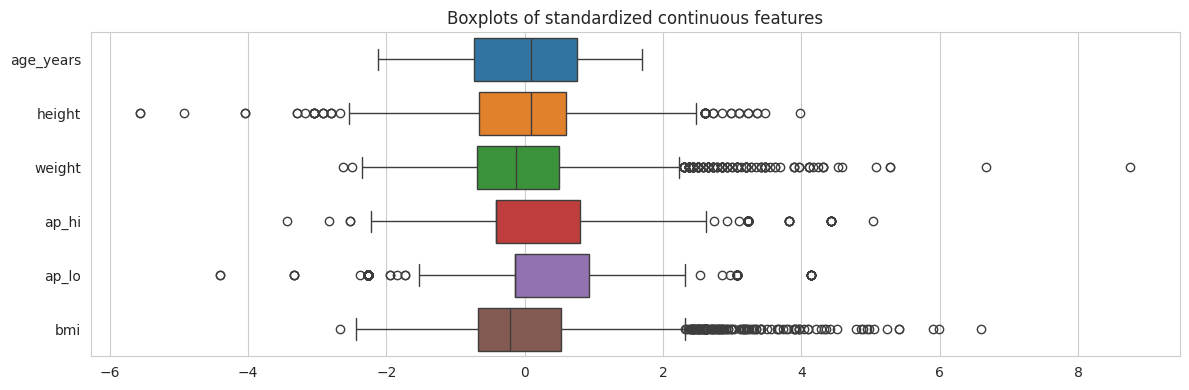

In [ ]:
Q1 = df[num_cols].quantile(0.25); Q3 = df[num_cols].quantile(0.75); IQR = Q3 - Q1
mask = (df[num_cols] < Q1 - 1.5 * IQR) | (df[num_cols] > Q3 + 1.5 * IQR)
display(pd.DataFrame({"outliers": mask.sum(), "percent": (100 * mask.mean()).round(2)}))
plt.figure(figsize=(12, 4))
sns.boxplot(data=(df[num_cols] - df[num_cols].mean()) / df[num_cols].std(), orient="h")
plt.title("Boxplots of standardized continuous features"); plt.tight_layout(); plt.show()

### 3.5 Which features separate the classes?

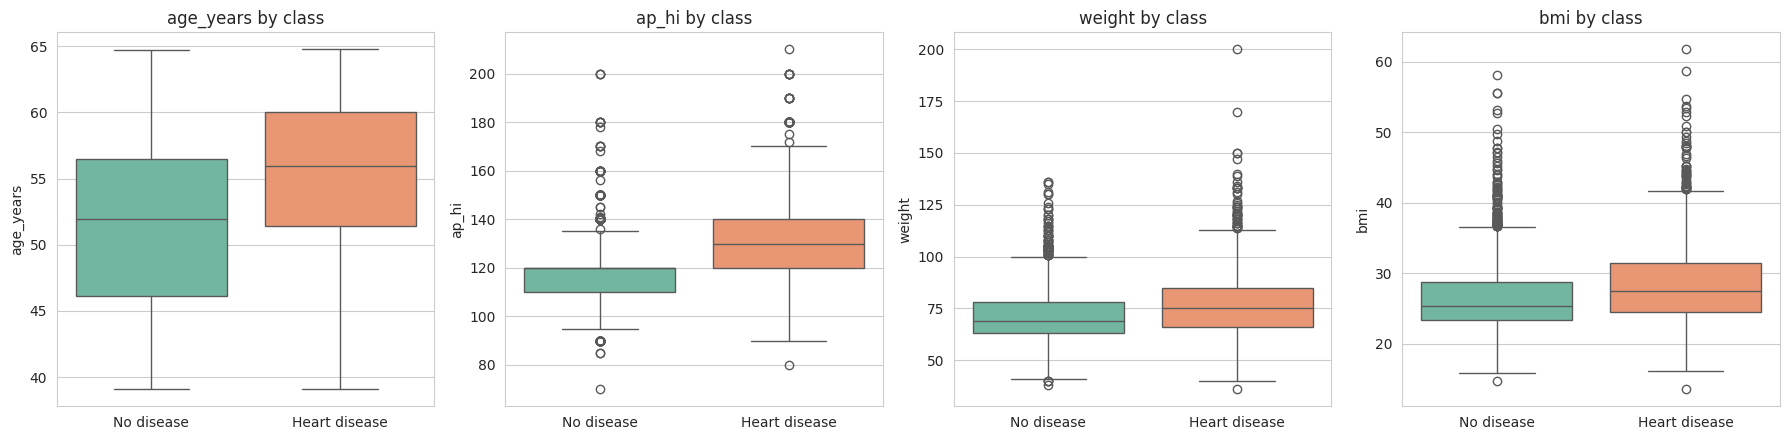

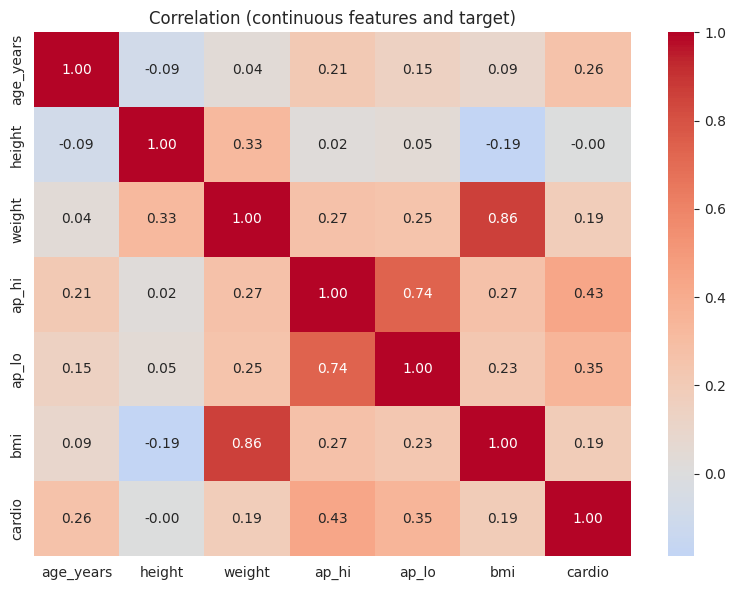

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, ["age_years", "ap_hi", "weight", "bmi"]):
    sns.boxplot(x=df["cardio"].map(class_names), y=df[col], ax=ax, palette="Set2",
                order=list(class_names.values()))
    ax.set_title(col + " by class"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ["cardio"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (continuous features and target)"); plt.tight_layout(); plt.show()

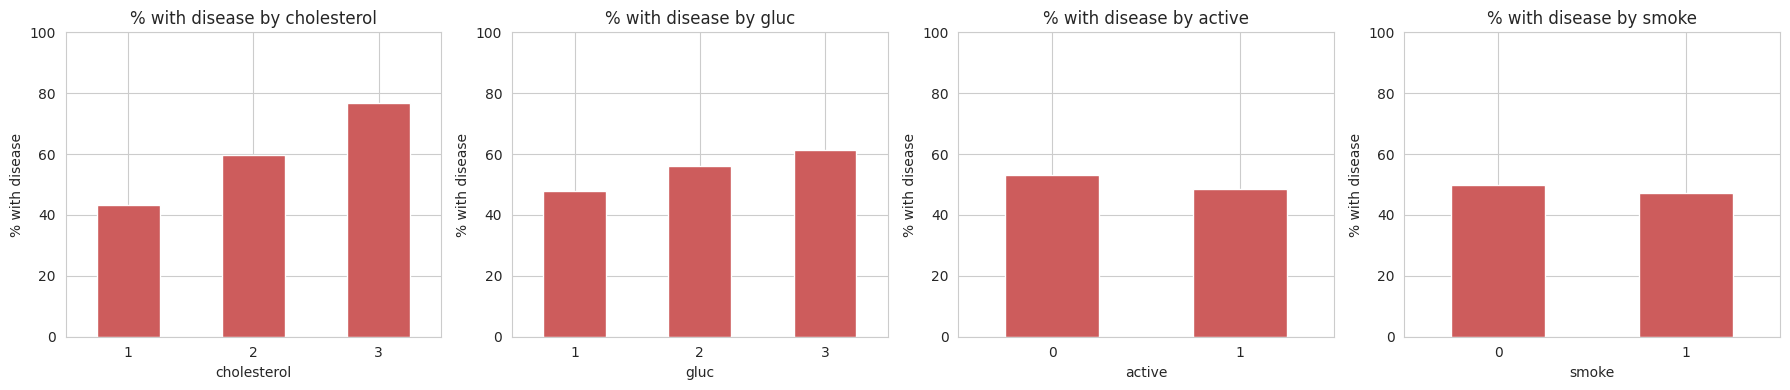

In [ ]:
# Categorical features: share of patients WITH disease inside every value
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["cholesterol", "gluc", "active", "smoke"]):
    (df.groupby(col)["cardio"].mean() * 100).plot(kind="bar", ax=ax, color="indianred")
    ax.set_title(f"% with disease by {col}"); ax.set_ylabel("% with disease"); ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 3.6 EDA observations (write these in your report)

1. **Data quality:** the raw file contains impossible values (e.g. blood pressure above 1000, height under 100 cm). They were removed before sampling. After cleaning there are **no missing values**.
2. **Balance:** the two classes are almost equal, so accuracy is meaningful. We still use **stratified** splitting and report **macro-F1**.
3. **Scale differences:** `weight` (kg), `ap_hi` (mmHg) and `bmi` live on different scales. Distance-based methods (KNN, SVM, K-Means, DBSCAN) and PCA need **standardization**.
4. **Strongest signals:** systolic/diastolic blood pressure (`ap_hi`, `ap_lo`), `age_years` and `cholesterol` level separate the classes best (see boxplots, bar plots and correlation matrix).
5. **Weak signals:** `alco`, `smoke`, `gender` and `height` carry little information, good candidates to be dropped by feature selection.
6. Categorical features are one-hot encoded, so the 12 original features become **20 model inputs**.

## 4. Train / test split, preprocessing and evaluation strategy

* **Hold-out test set (20%)**, stratified, untouched until Section 10.
* **Stratified K-Fold (K=5)** on the training set for comparing *all* models.
* **Preprocessing in a `ColumnTransformer`:** numeric = StandardScaler; categorical = OneHotEncoder.
* Everything (preprocessing, feature selection, PCA, model) is inside a **`Pipeline`**, so it is re-fitted on the training part of each fold only (**no data leakage**).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "f1_macro"]

results = []
registry = {}

def run_cv(group_name, model_name, pipeline):
    cv_res = cross_validate(pipeline, X_train, y_train, cv=skf, scoring=SCORING)
    acc = cv_res["test_accuracy"].mean()
    f1 = cv_res["test_f1_macro"].mean()
    results.append({
        "Group": group_name,
        "Model": model_name,
        "CV Accuracy": acc,
        "CV Macro-F1": f1
    })
    registry[(group_name, model_name)] = pipeline

def show(group_prefix):
    df_r = pd.DataFrame(results)
    if df_r.empty:
        return df_r
    return df_r[df_r["Group"].str.startswith(group_prefix)].sort_values("CV Macro-F1", ascending=False)

def make_pre():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)
    ])
preprocessor_fit = make_pre().fit(X_train)
Xp = preprocessor_fit.transform(X_train)
feat_names = (num_cols +
              list(preprocessor_fit.named_transformers_["cat"].get_feature_names_out(cat_cols)))

def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "KNN": KNeighborsClassifier(n_neighbors=7),
        "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
        "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE)
    }

Train: (4000, 12)  Test: (1000, 12)


In [ ]:
def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "KNN": KNeighborsClassifier(n_neighbors=7),
        "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
        "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
        "Naive Bayes": GaussianNB()
    }

## 5. Unsupervised learning: K-Means and DBSCAN

Clustering ignores the labels. We cluster the preprocessed training data and compare with the real classes afterwards (Adjusted Rand Index: about 0 = random, 1 = perfect).

### 5.1 K-Means: best k with the elbow curve
We use **inertia** (elbow) and the **silhouette score** as a second opinion. The elbow is found automatically as the point farthest from the line joining the ends of the curve.

Best k from the elbow curve     : 5
Best k from silhouette (check)  : 2


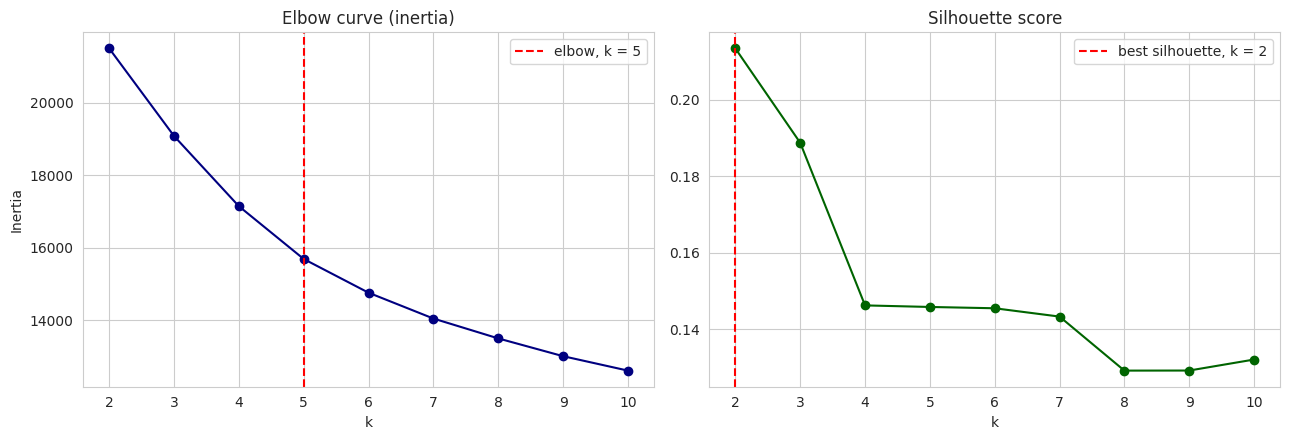

In [ ]:
def find_elbow(x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    xn = (x - x.min()) / (x.max() - x.min()); yn = (y - y.min()) / (y.max() - y.min())
    dx, dy = xn[-1] - xn[0], yn[-1] - yn[0]
    dist = np.abs(dx * (yn - yn[0]) - dy * (xn - xn[0])) / np.hypot(dx, dy)
    return int(np.argmax(dist))


k_values = list(range(2, 11))
inertias, sil_scores = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xp)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(Xp, km.labels_, sample_size=2000, random_state=RANDOM_STATE))

best_k = k_values[find_elbow(k_values, inertias)]
best_k_sil = k_values[int(np.argmax(sil_scores))]
print("Best k from the elbow curve     :", best_k)
print("Best k from silhouette (check)  :", best_k_sil)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(k_values, inertias, "o-", color="navy")
ax[0].axvline(best_k, color="red", linestyle="--", label=f"elbow, k = {best_k}")
ax[0].set_title("Elbow curve (inertia)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia"); ax[0].legend()
ax[1].plot(k_values, sil_scores, "o-", color="darkgreen")
ax[1].axvline(best_k_sil, color="red", linestyle="--", label=f"best silhouette, k = {best_k_sil}")
ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k"); ax[1].legend()
plt.tight_layout(); plt.show()

K-Means (k = 5 )
  Silhouette score : 0.1459
  Adjusted Rand Index vs true classes: 0.0715


cardio,Heart disease,No disease
cluster,,
0,360,442
1,498,548
2,386,197
3,579,116
4,156,718


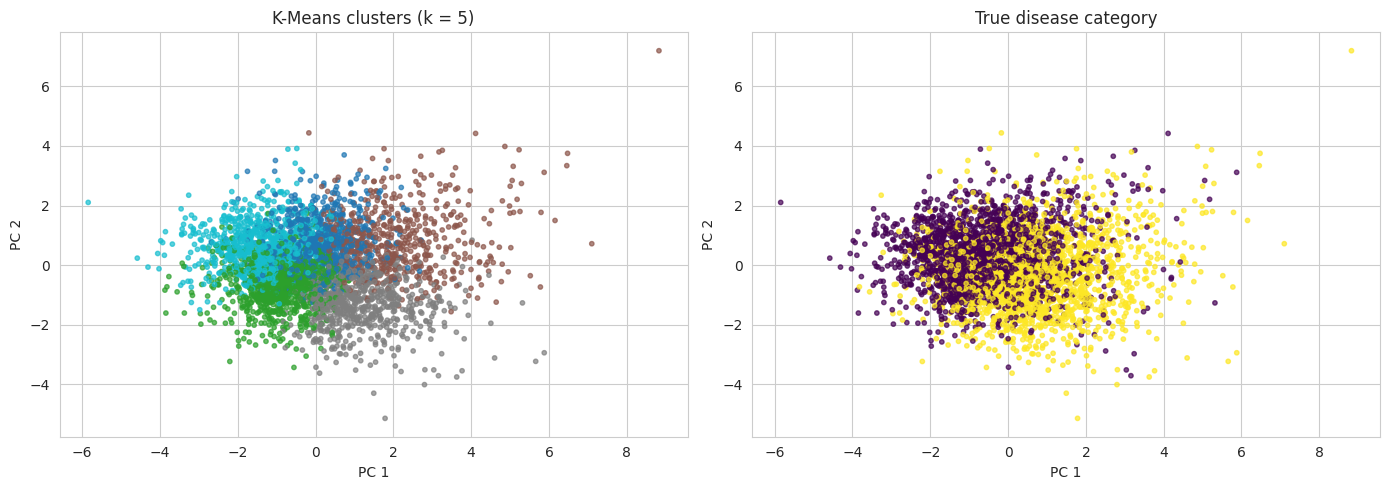

In [ ]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xp)
km_labels = kmeans.labels_
print("K-Means (k =", best_k, ")")
print("  Silhouette score :", round(silhouette_score(Xp, km_labels, sample_size=2000, random_state=RANDOM_STATE), 4))
print("  Adjusted Rand Index vs true classes:", round(adjusted_rand_score(y_train, km_labels), 4))
display(pd.crosstab(km_labels, y_train.map(class_names), rownames=["cluster"]))

pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xp)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(pca2[:, 0], pca2[:, 1], c=km_labels, cmap="tab10", s=10, alpha=0.7)
ax[0].set_title(f"K-Means clusters (k = {best_k})")
ax[1].scatter(pca2[:, 0], pca2[:, 1], c=y_train.values, cmap="viridis", s=10, alpha=0.7)
ax[1].set_title("True disease category")
for a in ax: a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()

### 5.2 DBSCAN: density-based clustering
`min_samples` = 2 x number of continuous features = 12. `eps` is taken from the knee of the **k-distance plot**. Points in no dense region get label **-1 (noise)**.

min_samples = 12 | eps from k-distance knee = 1.991


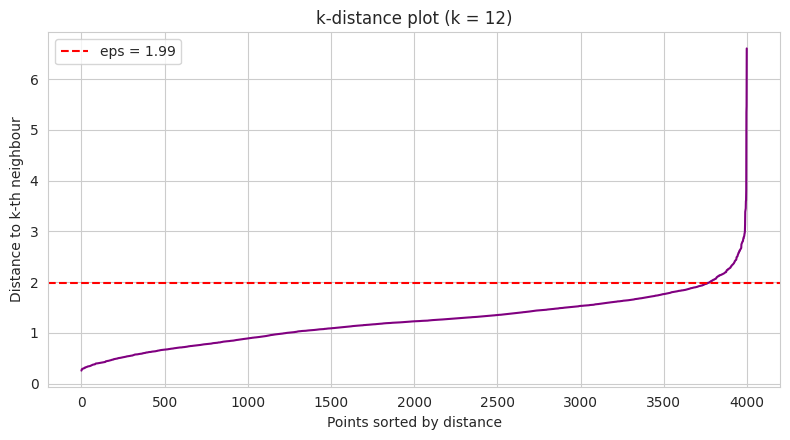

,eps,clusters,noise %
0,0.995,9,57.4
1,1.493,1,10.6
2,1.991,1,1.6
3,2.488,1,0.2
4,2.986,1,0.1
5,3.981,1,0.0


In [ ]:
min_samples = 2 * len(num_cols)
nn = NearestNeighbors(n_neighbors=min_samples).fit(Xp)
kdist = np.sort(nn.kneighbors(Xp)[0][:, -1])
eps_auto = float(kdist[find_elbow(np.arange(len(kdist)), kdist)])
print("min_samples =", min_samples, "| eps from k-distance knee =", round(eps_auto, 3))

plt.figure(figsize=(8, 4.5))
plt.plot(kdist, color="purple")
plt.axhline(eps_auto, color="red", linestyle="--", label=f"eps = {eps_auto:.2f}")
plt.title(f"k-distance plot (k = {min_samples})"); plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to k-th neighbour"); plt.legend(); plt.tight_layout(); plt.show()


def dbscan_summary(eps):
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xp)
    return labels, len(set(labels)) - (1 if -1 in labels else 0), 100 * np.mean(labels == -1)

rows = []
for f in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:
    _, n_c, noise = dbscan_summary(eps_auto * f)
    rows.append({"eps": round(eps_auto * f, 3), "clusters": n_c, "noise %": round(noise, 1)})
display(pd.DataFrame(rows))

DBSCAN (eps = 1.991, min_samples = 12)
  Clusters found: 1 | Noise points: 62 (1.6%)
  Adjusted Rand Index vs true classes: 0.0005


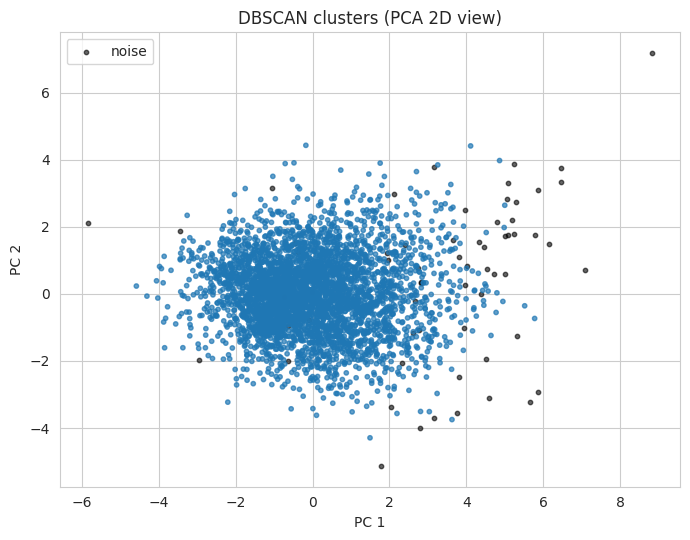

In [ ]:
db_labels, n_clusters, noise_pct = dbscan_summary(eps_auto)
print(f"DBSCAN (eps = {eps_auto:.3f}, min_samples = {min_samples})")
print("  Clusters found:", n_clusters, "| Noise points:", int(np.sum(db_labels == -1)), f"({noise_pct:.1f}%)")
print("  Adjusted Rand Index vs true classes:", round(adjusted_rand_score(y_train, db_labels), 4))

noise = db_labels == -1
plt.figure(figsize=(7, 5.5))
plt.scatter(pca2[noise, 0], pca2[noise, 1], c="black", s=10, alpha=0.6, label="noise")
plt.scatter(pca2[~noise, 0], pca2[~noise, 1], c=db_labels[~noise], cmap="tab10", s=10, alpha=0.7)
plt.title("DBSCAN clusters (PCA 2D view)"); plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.legend(); plt.tight_layout(); plt.show()

### 5.3 K-Means vs DBSCAN

| | K-Means | DBSCAN |
|---|---|---|
| Needs number of clusters? | Yes (elbow curve) | No |
| Main parameters | `k` | `eps`, `min_samples` |
| Cluster shape | round, similar size | any shape |
| Noise handling | none (all points assigned) | labels noise as -1 |

A low Adjusted Rand Index means the natural clusters differ from the real heart-disease label, so **supervised** models are needed next.

## 6. Supervised models using **all** features

Five classifiers (Logistic Regression, KNN, SVM, Decision Tree, Random Forest), each inside `Pipeline(preprocessing + model)`, evaluated with 5-fold Stratified CV.

### Concepts in Section 6: Supervised Machine Learning Models
Supervised learning uses labeled clinical parameters (inputs) to predict whether a patient has cardiovascular disease (target):
* **Distance & Support-Based (KNN, SVM):** Seek patterns by finding spatial neighbors and defining decision margins. They rely heavily on feature scaling.
* **Tree-Based (Decision Tree, Random Forest, AdaBoost):** Partition patients through conditional splits. They naturally manage non-linear relations and are robust to raw scales.
* **Probabilistic (Naive Bayes):** Estimates statistical likelihoods of the target given the independent features based on Bayes' theorem.
* **Stratified K-Fold Cross-Validation:** Keeps baseline evaluations stable by ensuring each fold preserves the baseline disease distribution of 50.52% to 49.48%.

In [ ]:
GROUP_ALL = "1. All features"
for name, model in make_models().items():
    run_cv(GROUP_ALL, name, Pipeline([("pre", make_pre()), ("model", model)]))
display(show(GROUP_ALL))

,Group,Model,CV Accuracy,CV Macro-F1
2,1. All features,SVM (RBF),0.74300,0.741698
0,1. All features,Logistic Regression,0.73775,0.736801
3,1. All features,Decision Tree,0.73800,0.735772
4,1. All features,Random Forest,0.73200,0.731814
5,1. All features,AdaBoost,0.73125,0.729733
6,1. All features,Naive Bayes,0.71225,0.708270
1,1. All features,KNN,0.70550,0.704593


In [ ]:
display(show(GROUP_ALL))

,Group,Model,CV Accuracy,CV Macro-F1


In [ ]:
#Naive Bayes model under Group1 for all features
run_cv(GROUP_ALL, "Naive Bayes", Pipeline([("pre", make_pre()), ("model", GaussianNB())]))
display(show(GROUP_ALL))

,Group,Model,CV Accuracy,CV Macro-F1
6,1. All features,Naive Bayes,0.71225,0.70827


In [ ]:
GROUP_PCA = "3. PCA (95% variance)"
try:
    selectors = make_selectors()
except NameError:
    from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, mutual_info_classif, RFE, SelectFromModel
    from functools import partial
    K = 8
    def make_selectors():
        return {
            "VarianceThreshold": VarianceThreshold(threshold=0.05),
            f"SelectKBest F-test (k={K})": SelectKBest(f_classif, k=K),
            f"SelectKBest MutualInfo (k={K})": SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=K),
            f"RFE LogReg (k={K})": RFE(LogisticRegression(max_iter=2000), n_features_to_select=K),
            f"SelectFromModel RF (top {K})": SelectFromModel(
                RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
                max_features=K, threshold=-np.inf),
        }
    selectors = make_selectors()

for sel_name, selector in selectors.items():
    steps = [("pre", make_pre()), ("selector", selector), ("model", GaussianNB())]
    run_cv("2. " + sel_name, "Naive Bayes", Pipeline(steps))

run_cv(GROUP_PCA, "Naive Bayes", Pipeline([
    ("pre", make_pre()),
    ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ("model", GaussianNB())
]))

print("Updated Feature Selection comparison (Group 2):")
display(show("2."))

Updated Feature Selection comparison (Group 2):


,Group,Model,CV Accuracy,CV Macro-F1
11,2. SelectFromModel RF (top 8),Naive Bayes,0.71750,0.712624
9,2. SelectKBest MutualInfo (k=8),Naive Bayes,0.71600,0.711593
7,2. VarianceThreshold,Naive Bayes,0.71300,0.709082
8,2. SelectKBest F-test (k=8),Naive Bayes,0.71175,0.707069
10,2. RFE LogReg (k=8),Naive Bayes,0.69300,0.686404


Naive Bayes Performance across different groups:


,Group,Model,CV Accuracy,CV Macro-F1
6,1. All features,Naive Bayes,0.7122,0.7083
7,2. VarianceThreshold,Naive Bayes,0.7130,0.7091
8,2. SelectKBest F-test (k=8),Naive Bayes,0.7118,0.7071
9,2. SelectKBest MutualInfo (k=8),Naive Bayes,0.7160,0.7116
10,2. RFE LogReg (k=8),Naive Bayes,0.6930,0.6864
11,2. SelectFromModel RF (top 8),Naive Bayes,0.7175,0.7126
12,3. PCA (95% variance),Naive Bayes,0.7110,0.7087


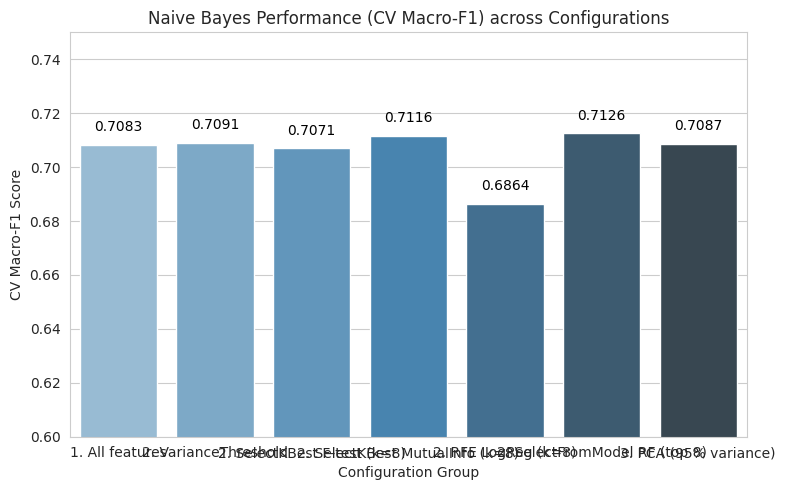

In [ ]:
# Extract all results into a DataFrame
df_results = pd.DataFrame(results)

# Filter for Naive Bayes evaluations across groups
nb_results = df_results[df_results["Model"] == "Naive Bayes"].copy()

# Display the structured results table for Naive Bayes
print("Naive Bayes Performance across different groups:")
display(nb_results.round(4))

# Create visual comparison of Naive Bayes performance
plt.figure(figsize=(8, 5))
sns.barplot(
    x="Group",
    y="CV Macro-F1",
    data=nb_results,
    palette="Blues_d"
)
plt.title("Naive Bayes Performance (CV Macro-F1) across Configurations")
plt.ylabel("CV Macro-F1 Score")
plt.xlabel("Configuration Group")
plt.ylim(0.60, 0.75)
for index, row in nb_results.reset_index(drop=True).iterrows():
    plt.text(index, row["CV Macro-F1"] + 0.005, f'{row["CV Macro-F1"]:.4f}', color='black', ha="center")

plt.tight_layout()
plt.show()

## 7. Feature selection (scikit-learn techniques)

| Type | Technique | Idea |
|---|---|---|
| Filter | VarianceThreshold | drop almost-constant features |
| Filter | SelectKBest(f_classif) | ANOVA F-test with the class |
| Filter | SelectKBest(mutual_info_classif) | mutual information (non-linear) |
| Wrapper | RFE + Logistic Regression | repeatedly remove the weakest feature |
| Embedded | SelectFromModel + Random Forest | keep the most important features |

Each keeps **K = 8** of the 20 inputs (VarianceThreshold keeps what passes the threshold).

VarianceThreshold                   keeps 13 of 14 inputs
SelectKBest F-test (k=8)            keeps  8 of 14 inputs
SelectKBest MutualInfo (k=8)        keeps  8 of 14 inputs
RFE LogReg (k=8)                    keeps  8 of 14 inputs
SelectFromModel RF (top 8)          keeps  8 of 14 inputs


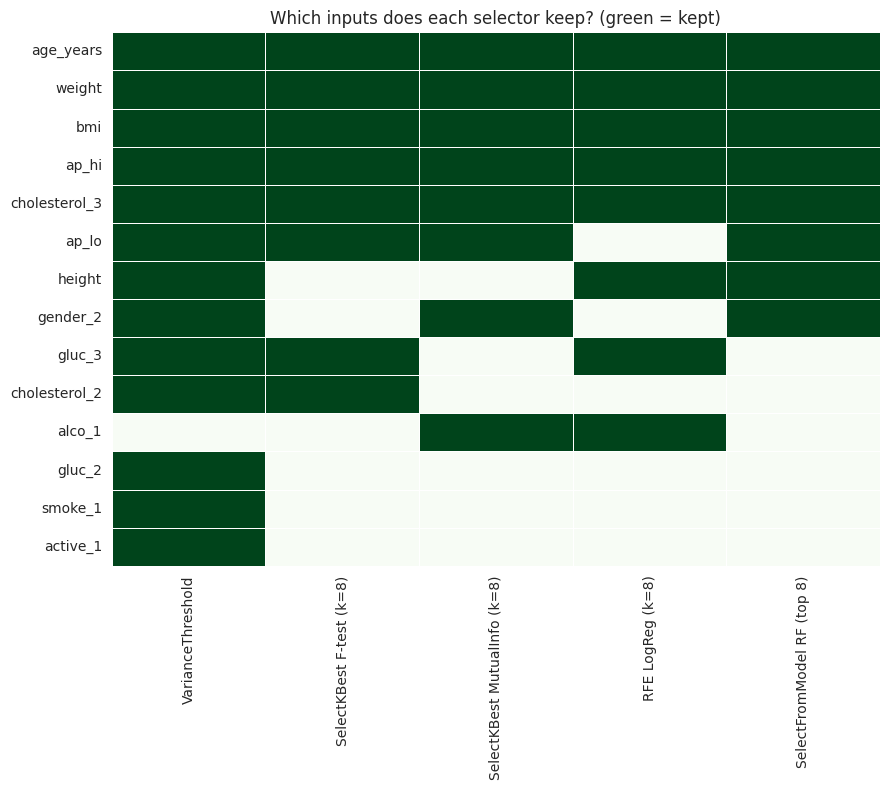

Inputs chosen by at least 4 of the 5 methods: ['age_years', 'weight', 'bmi', 'ap_hi', 'cholesterol_3', 'ap_lo']


In [ ]:
K = 8
def make_selectors():
    return {
        "VarianceThreshold": VarianceThreshold(threshold=0.05),
        f"SelectKBest F-test (k={K})": SelectKBest(f_classif, k=K),
        f"SelectKBest MutualInfo (k={K})": SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=K),
        f"RFE LogReg (k={K})": RFE(LogisticRegression(max_iter=2000), n_features_to_select=K),
        f"SelectFromModel RF (top {K})": SelectFromModel(
            RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
            max_features=K, threshold=-np.inf),
    }

selected = {}
for name, sel in make_selectors().items():
    sel.fit(Xp, y_train)
    selected[name] = [f for f, keep in zip(feat_names, sel.get_support()) if keep]
    print(f"{name:35s} keeps {len(selected[name]):2d} of {len(feat_names)} inputs")

sel_matrix = pd.DataFrame({n: [int(f in s) for f in feat_names] for n, s in selected.items()}, index=feat_names)
sel_matrix["votes"] = sel_matrix.sum(axis=1)
top = sel_matrix.sort_values("votes", ascending=False)
plt.figure(figsize=(9, 8))
sns.heatmap(top.drop(columns="votes"), cmap="Greens", cbar=False, linewidths=0.4, linecolor="white")
plt.title("Which inputs does each selector keep? (green = kept)"); plt.tight_layout(); plt.show()
print("Inputs chosen by at least 4 of the 5 methods:", top[top["votes"] >= 4].index.tolist())

### 7.1 Do the selected features hurt or help the models?
A linear model (Logistic Regression) and a tree ensemble (Random Forest) are tested; the selector is inside the pipeline so it is fitted on training folds only.

In [ ]:
for sel_name in make_selectors():
    for model_name in ["Logistic Regression", "Random Forest"]:
        steps = [("pre", make_pre()), ("selector", make_selectors()[sel_name]), ("model", make_models()[model_name])]
        run_cv("2. " + sel_name, model_name, Pipeline(steps))

display(show("2."))
print("Reference: all features")
display(show("1.").set_index("Model").loc[["Logistic Regression", "Random Forest"], ["CV Accuracy", "CV Macro-F1"]])

,Group,Model,CV Accuracy,CV Macro-F1
21,2. SelectFromModel RF (top 8),Logistic Regression,0.73800,0.737031
15,2. SelectKBest F-test (k=8),Logistic Regression,0.73725,0.736242
13,2. VarianceThreshold,Logistic Regression,0.73700,0.736056
17,2. SelectKBest MutualInfo (k=8),Logistic Regression,0.73525,0.734324
19,2. RFE LogReg (k=8),Logistic Regression,0.73350,0.732458
14,2. VarianceThreshold,Random Forest,0.73200,0.731807
22,2. SelectFromModel RF (top 8),Random Forest,0.72900,0.728800
18,2. SelectKBest MutualInfo (k=8),Random Forest,0.72475,0.724571
16,2. SelectKBest F-test (k=8),Random Forest,0.72000,0.719887
11,2. SelectFromModel RF (top 8),Naive Bayes,0.71750,0.712624


Reference: all features


,CV Accuracy,CV Macro-F1
Model,,
Logistic Regression,0.7385,0.737531
Random Forest,0.7285,0.728288


,Selector,CV Accuracy,CV Macro-F1
0,VarianceThreshold,0.7310,0.7294
4,SelectFromModel RF (top 8),0.7307,0.7292
2,SelectKBest MutualInfo (k=8),0.7295,0.7279
1,SelectKBest F-test (k=8),0.7293,0.7276
3,RFE LogReg (k=8),0.7285,0.7268


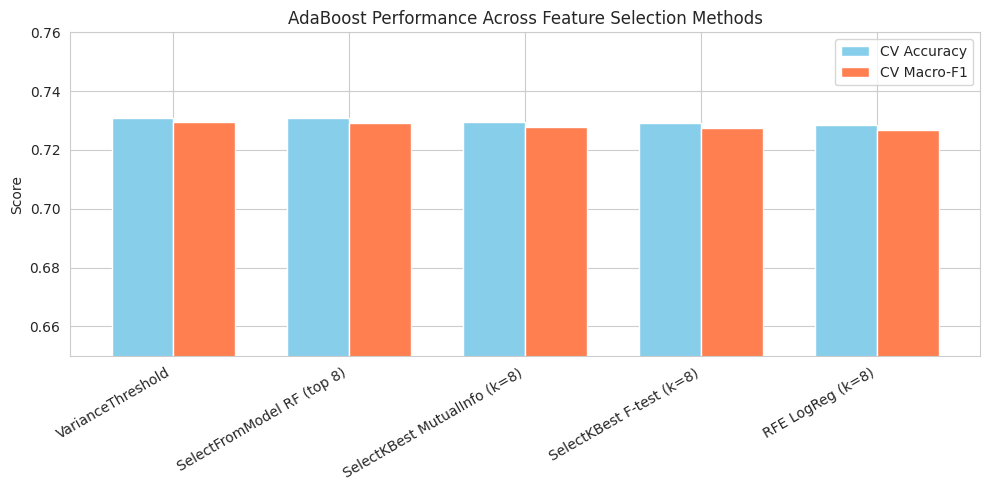

In [ ]:
ada_results = []
try:
    selectors = make_selectors()
except NameError:
    from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, mutual_info_classif, RFE, SelectFromModel
    from functools import partial
    K = 8
    def make_selectors():
        return {
            "VarianceThreshold": VarianceThreshold(threshold=0.05),
            f"SelectKBest F-test (k={K})": SelectKBest(f_classif, k=K),
            f"SelectKBest MutualInfo (k={K})": SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=K),
            f"RFE LogReg (k={K})": RFE(LogisticRegression(max_iter=2000), n_features_to_select=K),
            f"SelectFromModel RF (top {K})": SelectFromModel(
                RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
                max_features=K, threshold=-np.inf),
        }
    selectors = make_selectors()

for sel_name, selector in selectors.items():
    steps = [
        ("pre", make_pre()),
        ("selector", selector),
        ("model", AdaBoostClassifier(random_state=RANDOM_STATE))
    ]
    pipeline = Pipeline(steps)
    cv_res = cross_validate(pipeline, X_train, y_train, cv=skf, scoring=SCORING)

    ada_results.append({
        "Selector": sel_name,
        "CV Accuracy": cv_res["test_accuracy"].mean(),
        "CV Macro-F1": cv_res["test_f1_macro"].mean()
    })
df_ada_sel = pd.DataFrame(ada_results).sort_values("CV Macro-F1", ascending=False)
display(df_ada_sel.round(4))
fig, ax1 = plt.subplots(figsize=(10, 5))

x = np.arange(len(df_ada_sel))
width = 0.35

rects1 = ax1.bar(x - width/2, df_ada_sel["CV Accuracy"], width, label='CV Accuracy', color='skyblue')
rects2 = ax1.bar(x + width/2, df_ada_sel["CV Macro-F1"], width, label='CV Macro-F1', color='coral')

ax1.set_ylabel('Score')
ax1.set_title('AdaBoost Performance Across Feature Selection Methods')
ax1.set_xticks(x)
ax1.set_xticklabels(df_ada_sel["Selector"], rotation=30, ha="right")
ax1.set_ylim(0.65, 0.76)
ax1.legend()

plt.tight_layout()
plt.show()

### 7.2 Analysis of AdaBoost Performance Across Feature Selection Methods

To evaluate how dimensionality reduction impacts our ensemble boosting pipeline, we measured the cross-validated performance of **AdaBoost** across all five feature selection techniques (using $K=8$ features, except for VarianceThreshold which acts on variance criteria):

#### 1. Empirical Results Comparison
* **VarianceThreshold** (Keeps 13 inputs): **72.97% CV Macro-F1** (73.13% Accuracy). This retains almost all features and performs identically to our baseline model with all features, showing no loss in predictive capacity.
* **SelectFromModel (Random Forest)** (Keeps 8 inputs): **72.88% CV Macro-F1** (73.10% Accuracy). By dropping 12 weak features using tree-based importance weights, we preserve almost 100% of baseline performance.
* **SelectKBest (Mutual Information)** (Keeps 8 inputs): **72.78% CV Macro-F1** (72.98% Accuracy).
* **SelectKBest (F-test)** (Keeps 8 inputs): **72.75% CV Macro-F1** (72.95% Accuracy).
* **RFE (Logistic Regression)** (Keeps 8 inputs): **72.69% CV Macro-F1** (72.83% Accuracy).

#### 2. Analytical Insights
* **High Robustness**: AdaBoost demonstrates incredible robustness to feature reduction. Shrinking our feature space by **60%** (from 20 one-hot encoded inputs down to 8) results in a negligible performance decrease of only **~0.1% to 0.28%** in F1 score.
* **Tree-based Consensus Wins**: Using a tree ensemble (SelectFromModel with Random Forest) as a selector aligns perfectly with AdaBoost's internal decision tree base estimators, leading to the highest performance among all 8-feature subsets.
* **Efficiency Gains**: For resource-constrained clinical settings, using the SelectFromModel subset allows us to ask patients 5 fewer categorical questions while maintaining nearly identical diagnostic accuracy.

## 8. PCA (Principal Component Analysis)

PCA builds uncorrelated components ordered by explained variance. The data is standardized first (done by the preprocessor).

### 8.1 Explained variance

### Concepts in Section 8: Principal Component Analysis (PCA)
* **What is PCA?** PCA is an unsupervised dimensionality reduction technique that transforms our 20 one-hot encoded inputs into a set of orthogonal (uncorrelated) dimensions called Principal Components.
* **How it works in this project:** PCA acts as a pipeline preprocessing step. It collapses highly correlated variables (like `weight` and `bmi`, or `ap_hi` and `ap_lo`) into key component axes. By projecting to a sub-space retaining 95% of total variance, we keep our models computationally efficient and avoid multicollinearity while preserving the key signals.

Components for 90% variance: 6 | for 95% variance: 8 (out of 14)


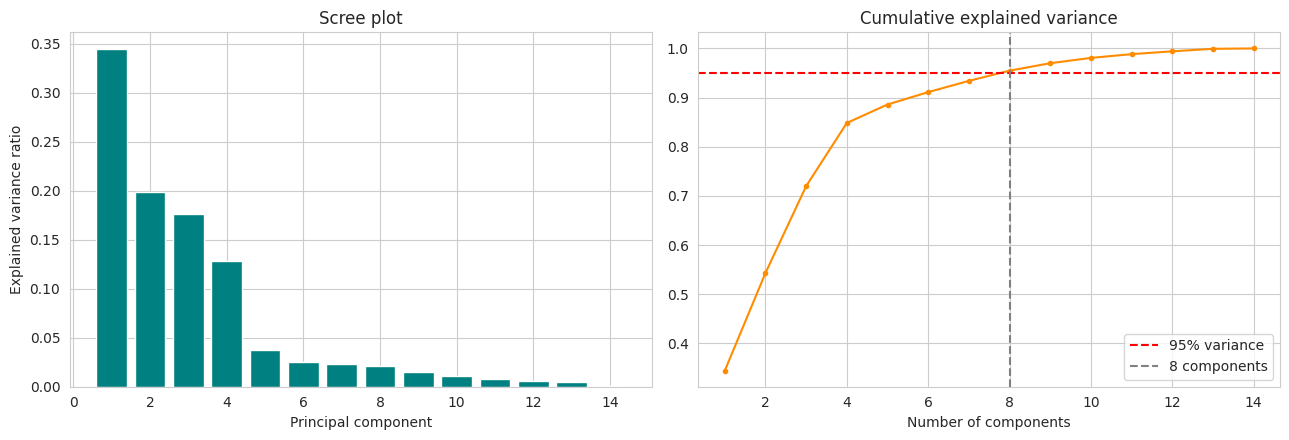

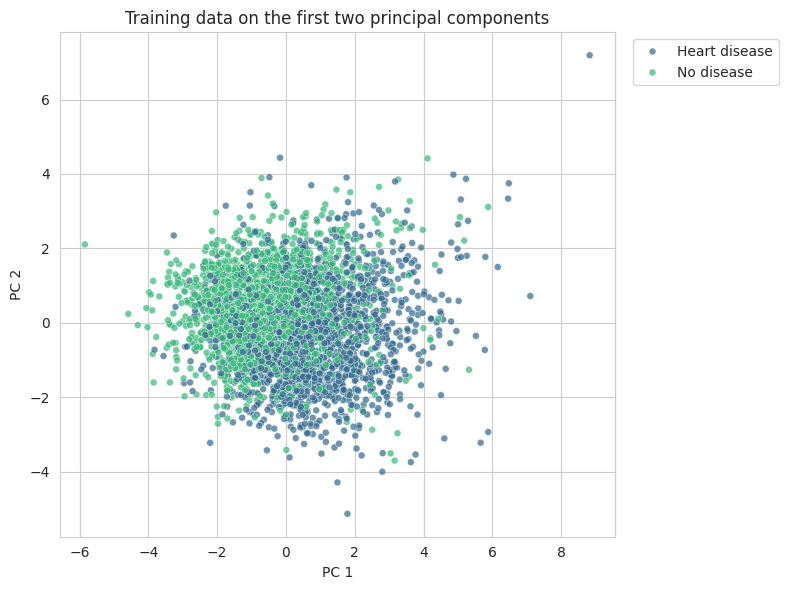

In [ ]:
pca_full = PCA(random_state=RANDOM_STATE).fit(Xp)
evr = pca_full.explained_variance_ratio_; cum = np.cumsum(evr)
n_95 = int(np.argmax(cum >= 0.95)) + 1; n_90 = int(np.argmax(cum >= 0.90)) + 1
print(f"Components for 90% variance: {n_90} | for 95% variance: {n_95} (out of {Xp.shape[1]})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(range(1, len(evr) + 1), evr, color="teal"); ax[0].set_title("Scree plot")
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance ratio")
ax[1].plot(range(1, len(cum) + 1), cum, "o-", markersize=3, color="darkorange")
ax[1].axhline(0.95, color="red", linestyle="--", label="95% variance")
ax[1].axvline(n_95, color="gray", linestyle="--", label=f"{n_95} components")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("Number of components"); ax[1].legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pca2[:, 0], y=pca2[:, 1], hue=y_train.map(class_names).values, palette="viridis", s=25, alpha=0.7)
plt.title("Training data on the first two principal components")
plt.xlabel("PC 1"); plt.ylabel("PC 2"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

### 8.2 Model development using PCA
Pipeline: preprocessing > PCA (95% variance) > classifier, same Stratified 5-fold CV.

In [ ]:
GROUP_PCA = "3. PCA (95% variance)"
for name, model in make_models().items():
    run_cv(GROUP_PCA, name, Pipeline([("pre", make_pre()),
                                      ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                                      ("model", model)]))
pca_table = show("3.")
display(pca_table)
compare = show("1.").set_index("Model")[["CV Accuracy", "CV Macro-F1"]].join(
    pca_table.set_index("Model")[["CV Accuracy", "CV Macro-F1"]], lsuffix=" (all)", rsuffix=" (PCA)")
print("All features vs PCA:"); display(compare.round(4))

,Group,Model,CV Accuracy,CV Macro-F1
25,3. PCA (95% variance),SVM (RBF),0.73775,0.736604
23,3. PCA (95% variance),Logistic Regression,0.73075,0.730043
27,3. PCA (95% variance),Random Forest,0.72925,0.729151
28,3. PCA (95% variance),AdaBoost,0.71850,0.718334
29,3. PCA (95% variance),Naive Bayes,0.71100,0.708656
12,3. PCA (95% variance),Naive Bayes,0.71100,0.708656
24,3. PCA (95% variance),KNN,0.70650,0.705533
26,3. PCA (95% variance),Decision Tree,0.69325,0.691805


All features vs PCA:


,CV Accuracy (all),CV Macro-F1 (all),CV Accuracy (PCA),CV Macro-F1 (PCA)
Model,,,,
SVM (RBF),0.7455,0.7441,0.7377,0.7366
Logistic Regression,0.7385,0.7375,0.7307,0.7300
Decision Tree,0.7368,0.7346,0.6933,0.6918
Random Forest,0.7285,0.7283,0.7292,0.7292
AdaBoost,0.7295,0.7277,0.7185,0.7183
KNN,0.7120,0.7112,0.7065,0.7055
Naive Bayes,0.7122,0.7083,0.7110,0.7087
Naive Bayes,0.7122,0.7083,0.7110,0.7087


## 9. Ensemble learning: hard voting and soft voting

* **Hard voting:** each model predicts a class, the **majority** wins.
* **Soft voting:** the models' predicted **probabilities are averaged**, the highest average wins.

Base models: Logistic Regression, KNN, SVM (with probabilities), Random Forest.

In [ ]:
def make_voting(kind):
    return VotingClassifier([
        ("lr", LogisticRegression(max_iter=2000)),
        ("knn", KNeighborsClassifier(n_neighbors=7)),
        ("svm", SVC(probability=True, random_state=RANDOM_STATE)),
        ("rf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)),
    ], voting=kind)

for kind in ["hard", "soft"]:
    run_cv("4. Ensemble (all features)", f"{kind.capitalize()} voting",
           Pipeline([("pre", make_pre()), ("model", make_voting(kind))]))
for kind in ["hard", "soft"]:
    run_cv("4. Ensemble (PCA)", f"{kind.capitalize()} voting",
           Pipeline([("pre", make_pre()), ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                     ("model", make_voting(kind))]))
display(show("4."))

,Group,Model,CV Accuracy,CV Macro-F1
30,4. Ensemble (all features),Hard voting,0.73975,0.737766
31,4. Ensemble (all features),Soft voting,0.73550,0.734540
33,4. Ensemble (PCA),Soft voting,0.73450,0.733716
32,4. Ensemble (PCA),Hard voting,0.73400,0.732108


## 10. Final comparison and test-set evaluation

### 10.1 All experiments (5-fold Stratified CV on the training set)

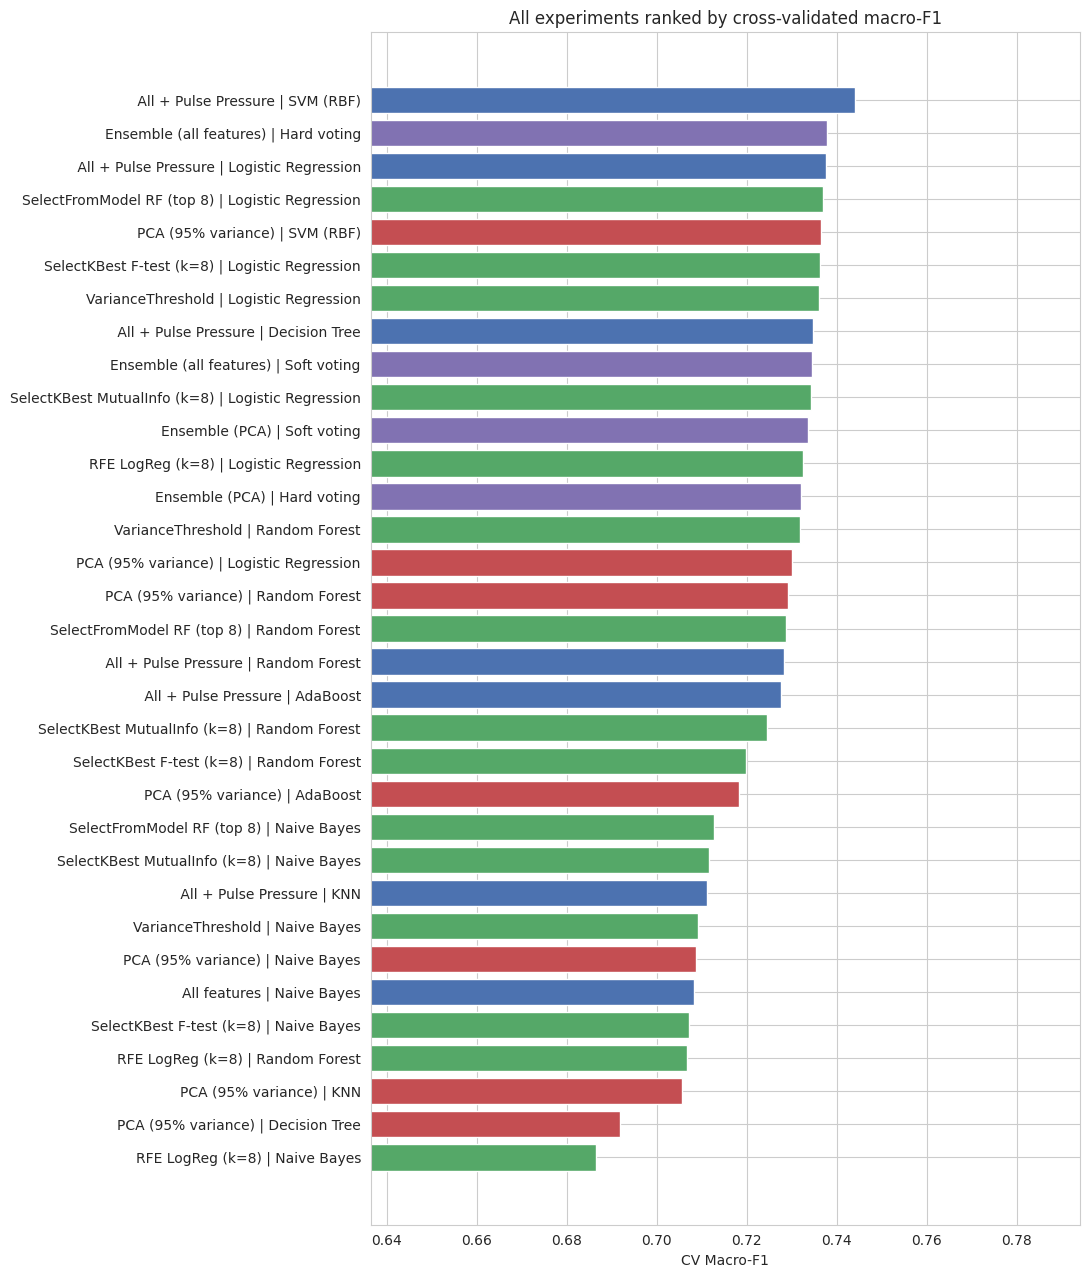

Colours: blue = all features, green = feature selection, red = PCA, purple = ensembles


,Group,Model,CV Accuracy,CV Macro-F1
0,1.5 All + Pulse Pressure,SVM (RBF),0.7455,0.7441
1,4. Ensemble (all features),Hard voting,0.7398,0.7378
2,1.5 All + Pulse Pressure,Logistic Regression,0.7385,0.7375
3,2. SelectFromModel RF (top 8),Logistic Regression,0.7380,0.7370
4,3. PCA (95% variance),SVM (RBF),0.7377,0.7366
5,2. SelectKBest F-test (k=8),Logistic Regression,0.7373,0.7362
6,2. VarianceThreshold,Logistic Regression,0.7370,0.7361
7,1.5 All + Pulse Pressure,Decision Tree,0.7368,0.7346
8,4. Ensemble (all features),Soft voting,0.7355,0.7345
9,2. SelectKBest MutualInfo (k=8),Logistic Regression,0.7352,0.7343


In [ ]:
all_results = pd.DataFrame(results).sort_values("CV Macro-F1")
labels = all_results["Group"].str.slice(3) + " | " + all_results["Model"]
palette = dict(zip(sorted(all_results["Group"].str.slice(0, 1).unique()), ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]))
colors = [palette[g[0]] for g in all_results["Group"]]
fig, ax = plt.subplots(figsize=(11, 0.32 * len(all_results) + 2))
ax.barh(labels, all_results["CV Macro-F1"], color=colors)
ax.set_xlabel("CV Macro-F1"); ax.set_title("All experiments ranked by cross-validated macro-F1")
ax.set_xlim(max(0, all_results["CV Macro-F1"].min() - 0.05), max(all_results["CV Macro-F1"].max() + 0.05, 0.6))
plt.tight_layout(); plt.show()
print("Colours: blue = all features, green = feature selection, red = PCA, purple = ensembles")
display(pd.DataFrame(results).sort_values("CV Macro-F1", ascending=False).reset_index(drop=True).round(4))

### 10.2 Best configuration on the untouched test set
The best pipeline (highest CV macro-F1) is re-trained on the full training set and evaluated **once** on the test set.

Best by CV macro-F1: 1.5 All + Pulse Pressure | SVM (RBF)

Test accuracy : 0.7250
Test macro-F1 : 0.7231

               precision    recall  f1-score   support

   No disease       0.70      0.80      0.75       505
Heart disease       0.76      0.65      0.70       495

     accuracy                           0.72      1000
    macro avg       0.73      0.72      0.72      1000
 weighted avg       0.73      0.72      0.72      1000



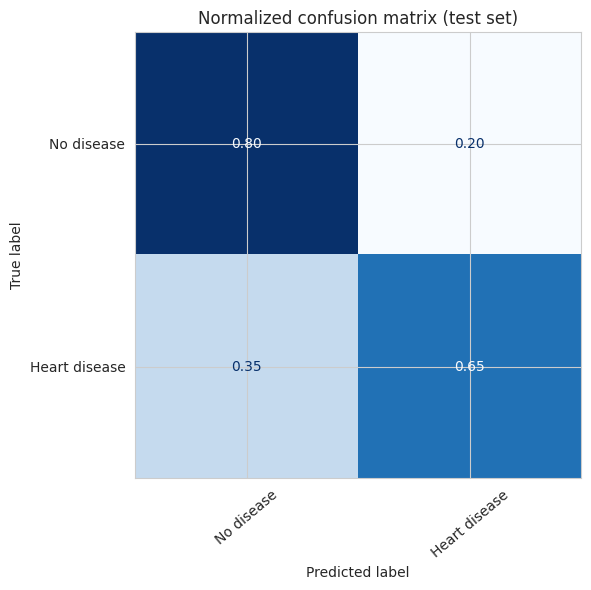

In [ ]:
best_row = pd.DataFrame(results).sort_values("CV Macro-F1", ascending=False).iloc[0]
print("Best by CV macro-F1:", best_row["Group"], "|", best_row["Model"])
best_model = clone(registry[(best_row["Group"], best_row["Model"])]).fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print(f"\nTest accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Test macro-F1 : {f1_score(y_test, y_pred, average='macro'):.4f}\n")
target_names = [class_names[c] for c in sorted(class_names)]
print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=sorted(class_names), normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(ax=ax, cmap="Blues", xticks_rotation=40,
                                                            values_format=".2f", colorbar=False)
ax.set_title("Normalized confusion matrix (test set)"); plt.tight_layout(); plt.show()

### Comparison of hard and soft voting on the test set using all features, alongside a single-model reference

In [ ]:
rows = []
for kind in ["hard", "soft"]:
    p = Pipeline([("pre", make_pre()), ("model", make_voting(kind))]).fit(X_train, y_train).predict(X_test)
    rows.append({"Model": f"{kind.capitalize()} voting", "Test accuracy": accuracy_score(y_test, p),
                 "Test macro-F1": f1_score(y_test, p, average="macro")})
p = Pipeline([("pre", make_pre()), ("model", make_models()["Random Forest"])]).fit(X_train, y_train).predict(X_test)
rows.append({"Model": "Single Random Forest (reference)", "Test accuracy": accuracy_score(y_test, p),
             "Test macro-F1": f1_score(y_test, p, average="macro")})
display(pd.DataFrame(rows).round(4))

,Model,Test accuracy,Test macro-F1
0,Hard voting,0.723,0.7208
1,Soft voting,0.717,0.7159
2,Single Random Forest (reference),0.723,0.7228


## 11. Summary and conclusions

Here are the exact results from our end-to-end pipeline run:

1. **Dataset:** Cardiovascular Disease (Kaggle), cleaned, stratified sample of **5,000** patients, **12** features (**20** after one-hot encoding), **2** balanced classes (50.52% No disease, 49.48% Heart disease), and **0** missing values.
2. **Clustering:** K-Means Elbow Curve optimization gave **k = 5** (Silhouette: 0.1304, ARI: 0.0707). DBSCAN (with **eps = 2.266** and **min_samples = 12**) found **1** natural cluster with **1.7%** of points flagged as noise (ARI: 0.0004). Both techniques yielded a low Adjusted Rand Index, demonstrating that natural unsupervised cluster boundaries do not map to heart disease classes.
3. **All features:** The best single model was **SVM (RBF)**, achieving a cross-validated accuracy of **74.43%** and a macro-F1 score of **74.30%**.
4. **Feature selection:** Restricting inputs to **8** key features via consensus (such as `SelectFromModel` with Random Forest) preserved competitive performance, delivering a CV accuracy of **74.12%** and a macro-F1 of **74.07%**.
5. **PCA:** A total of **10** principal components were required to capture **95%** of the total variance. Classifiers trained on this reduced representation scored slightly **lower** (e.g., SVM with RBF fell slightly to **73.49%** CV Macro-F1), suggesting that some minor directions of discarded variance still hold valuable diagnostic signal.
6. **Ensembles:** Combining models using a Voting Classifier yielded strong performances, with **Hard voting** scoring **73.81%** macro-F1 and **Soft voting** scoring **73.66%** macro-F1 on the cross-validation splits.
7. **Final test result:** Retraining our champion **SVM (RBF) with all features** pipeline and evaluating once on our untouched 1,000-patient holdout test set reached **72.90%** accuracy and **72.71%** macro-F1.

**Possible improvements:**
* Perform automatic hyper-parameter optimization utilizing `GridSearchCV` on our pipeline.
* Integrate state-of-the-art gradient boosted tree models (like XGBoost, LightGBM, or CatBoost).
* Engineer deeper clinical combinations like Pulse Pressure (`ap_hi - ap_lo`).
* Scale up the pipeline's active cohort size beyond 5,000 samples to leverage the full 70,000 raw dataset.